In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
amzn = pd.read_csv("../data/processed/amzn_market_clean.csv")
sp500 = pd.read_csv("../data/processed/sp500_market_clean.csv")

amzn["Date"] = pd.to_datetime(amzn["Date"])
sp500["Date"] = pd.to_datetime(sp500["Date"])

print("Amazon:")
print(amzn.head())

print("\nS&P 500:")
print(sp500.head())

Amazon:
        Date  Adj Close      Close       High        Low       Open    Volume  \
0 2018-01-02  59.450500  59.450500  59.500000  58.525501  58.599998  53890000   
1 2018-01-03  60.209999  60.209999  60.274502  59.415001  59.415001  62176000   
2 2018-01-04  60.479500  60.479500  60.793499  60.233002  60.250000  60442000   
3 2018-01-05  61.457001  61.457001  61.457001  60.500000  60.875500  70894000   
4 2018-01-08  62.343498  62.343498  62.653999  61.601501  61.799999  85590000   

   Daily_Return  
0           NaN  
1      0.012775  
2      0.004476  
3      0.016163  
4      0.014425  

S&P 500:
        Date    Adj Close        Close         High          Low         Open  \
0 2018-01-02  2695.810059  2695.810059  2695.889893  2682.360107  2683.729980   
1 2018-01-03  2713.060059  2713.060059  2714.370117  2697.770020  2697.850098   
2 2018-01-04  2723.989990  2723.989990  2729.290039  2719.070068  2719.310059   
3 2018-01-05  2743.149902  2743.149902  2743.449951  2727.91992

In [3]:
print("Amazon shape:", amzn.shape)
print("S&P 500 shape:", sp500.shape)

print("\nAmazon missing values:")
print(amzn.isnull().sum())

print("\nS&P 500 missing values:")
print(sp500.isnull().sum())

Amazon shape: (2011, 8)
S&P 500 shape: (2011, 9)

Amazon missing values:
Date            0
Adj Close       0
Close           0
High            0
Low             0
Open            0
Volume          0
Daily_Return    1
dtype: int64

S&P 500 missing values:
Date                 0
Adj Close            0
Close                0
High                 0
Low                  0
Open                 0
Volume               0
Daily_Return         1
Cumulative_Return    1
dtype: int64


In [4]:
amzn_mean_daily = amzn["Daily_Return"].mean()
sp500_mean_daily = sp500["Daily_Return"].mean()

print("Amazon average daily return:", amzn_mean_daily)
print("S&P 500 average daily return:", sp500_mean_daily)

Amazon average daily return: 0.0009097131618781463
S&P 500 average daily return: 0.0005401996974432203


In [5]:
amzn_annual_return = amzn["Daily_Return"].mean() * 252
sp500_annual_return = sp500["Daily_Return"].mean() * 252

print("Amazon annualized return:", amzn_annual_return)
print("Amazon annualized return (%):", amzn_annual_return * 100)

print("\nS&P 500 annualized return:", sp500_annual_return)
print("S&P 500 annualized return (%):", sp500_annual_return * 100)

Amazon annualized return: 0.22924771679329287
Amazon annualized return (%): 22.924771679329286

S&P 500 annualized return: 0.1361303237556915
S&P 500 annualized return (%): 13.613032375569151


In [6]:
amzn_volatility = amzn["Daily_Return"].std() * np.sqrt(252)
sp500_volatility = sp500["Daily_Return"].std() * np.sqrt(252)

print("Amazon annualized volatility:", amzn_volatility * 100, "%")
print("S&P 500 annualized volatility:", sp500_volatility * 100, "%")

Amazon annualized volatility: 34.4081024487597 %
S&P 500 annualized volatility: 19.600136467226793 %


In [7]:
amzn_sharpe = (
    amzn["Daily_Return"].mean() /
    amzn["Daily_Return"].std()
) * np.sqrt(252)

sp500_sharpe = (
    sp500["Daily_Return"].mean() /
    sp500["Daily_Return"].std()
) * np.sqrt(252)

print("Amazon Sharpe Ratio:", amzn_sharpe)
print("S&P 500 Sharpe Ratio:", sp500_sharpe)

Amazon Sharpe Ratio: 0.6662608527589888
S&P 500 Sharpe Ratio: 0.6945376323441104


In [8]:
amzn["Cumulative_Return"] = (1 + amzn["Daily_Return"]).cumprod()

amzn["Running_Peak"] = amzn["Cumulative_Return"].cummax()

amzn["Drawdown"] = (
    amzn["Cumulative_Return"] /
    amzn["Running_Peak"]
) - 1

max_drawdown = amzn["Drawdown"].min()

print("Amazon maximum drawdown:", max_drawdown)
print("Amazon maximum drawdown (%):", max_drawdown * 100)

Amazon maximum drawdown: -0.5614526325328254
Amazon maximum drawdown (%): -56.14526325328254


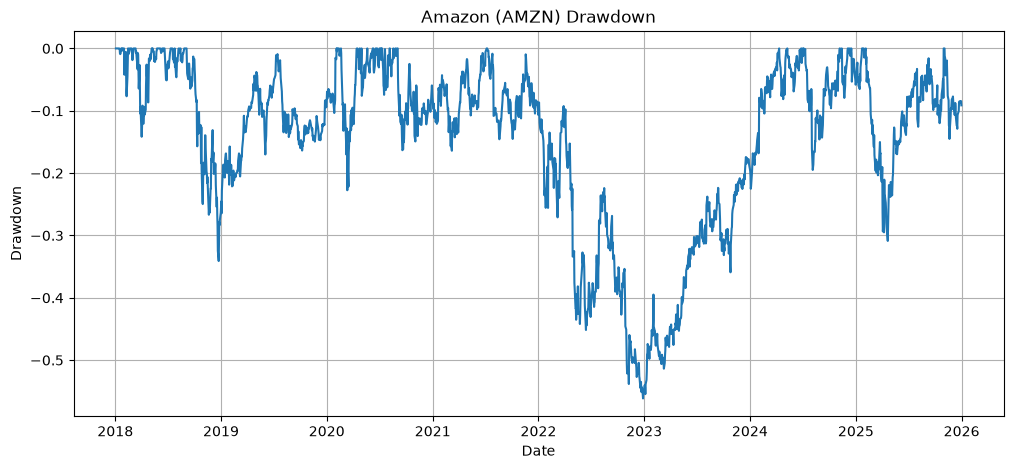

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    amzn["Date"],
    amzn["Drawdown"]
)

plt.title("Amazon (AMZN) Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.grid(True)

plt.show()

In [10]:
returns = pd.merge(
    amzn[["Date", "Daily_Return"]],
    sp500[["Date", "Daily_Return"]],
    on="Date",
    suffixes=("_AMZN", "_SP500")
)

returns.head()

,Date,Daily_Return_AMZN,Daily_Return_SP500
0,2018-01-02,NaN,NaN
1,2018-01-03,0.012775,0.006399
2,2018-01-04,0.004476,0.004029
3,2018-01-05,0.016163,0.007034
4,2018-01-08,0.014425,0.001662


In [11]:
correlation = returns["Daily_Return_AMZN"].corr(
    returns["Daily_Return_SP500"]
)

print("Amazon / S&P 500 correlation:", correlation)

Amazon / S&P 500 correlation: 0.6709204887762937


In [12]:
covariance = returns["Daily_Return_AMZN"].cov(
    returns["Daily_Return_SP500"]
)

market_variance = returns["Daily_Return_SP500"].var()

beta = covariance / market_variance

print("Amazon Beta:", beta)

Amazon Beta: 1.177803070472852


In [14]:
sp500["Cumulative_Return"] = (
    1 + sp500["Daily_Return"]
).cumprod()

sp500["Running_Peak"] = (
    sp500["Cumulative_Return"]
).cummax()

sp500["Drawdown"] = (
    sp500["Cumulative_Return"] /
    sp500["Running_Peak"]
) - 1

sp500_max_drawdown = sp500["Drawdown"].min()

print("S&P 500 maximum drawdown:", sp500_max_drawdown)
print(
    "S&P 500 maximum drawdown (%):",
    sp500_max_drawdown * 100
)

S&P 500 maximum drawdown: -0.33924960002653315
S&P 500 maximum drawdown (%): -33.924960002653314


In [16]:
summary = pd.DataFrame({
    "Metric": [
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown",
        "Correlation with S&P 500",
        "Beta"
    ],
    "Amazon": [
        amzn_annual_return,
        amzn_volatility,
        amzn_sharpe,
        max_drawdown,
        correlation,
        beta
    ],
    "S&P 500": [
        sp500_annual_return,
        sp500_volatility,
        sp500_sharpe,
sp500_max_drawdown,        1.0,
        1.0
    ]
})

summary

,Metric,Amazon,S&P 500
0,Annualized Return,0.229248,0.136130
1,Annualized Volatility,0.344081,0.196001
2,Sharpe Ratio,0.666261,0.694538
3,Maximum Drawdown,-0.561453,-0.339250
4,Correlation with S&P 500,0.670920,1.000000
5,Beta,1.177803,1.000000


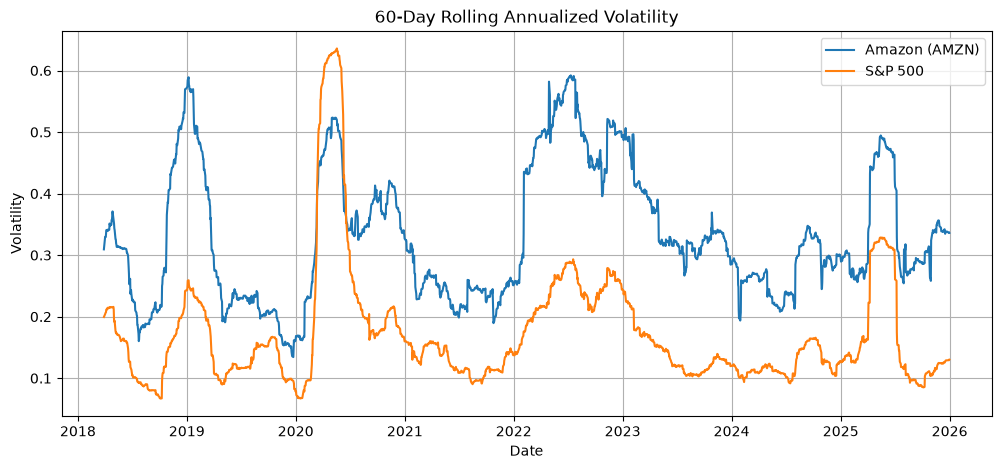

In [17]:
amzn["Rolling_Volatility"] = (
    amzn["Daily_Return"]
    .rolling(60)
    .std() * np.sqrt(252)
)

sp500["Rolling_Volatility"] = (
    sp500["Daily_Return"]
    .rolling(60)
    .std() * np.sqrt(252)
)

plt.figure(figsize=(12, 5))

plt.plot(
    amzn["Date"],
    amzn["Rolling_Volatility"],
    label="Amazon (AMZN)"
)

plt.plot(
    sp500["Date"],
    sp500["Rolling_Volatility"],
    label="S&P 500"
)

plt.title("60-Day Rolling Annualized Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)

plt.show()

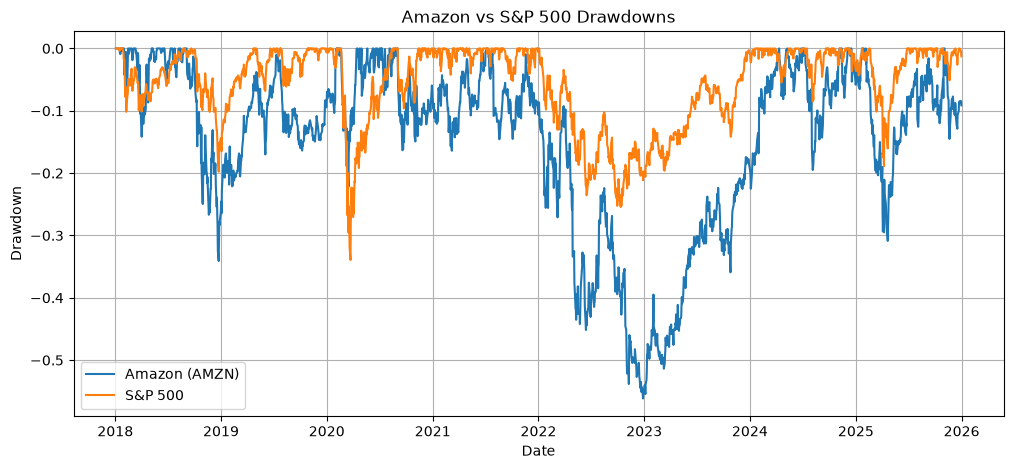

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    amzn["Date"],
    amzn["Drawdown"],
    label="Amazon (AMZN)"
)

plt.plot(
    sp500["Date"],
    sp500["Drawdown"],
    label="S&P 500"
)

plt.title("Amazon vs S&P 500 Drawdowns")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.grid(True)

plt.show()